<a href="https://colab.research.google.com/github/shaansanghvi-boop/pairs_trading_strategy/blob/main/FinalQuantProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
Quant Mentorship Final Project based on Pairs Trading between any two stocks
I have chosen Coke and Pepsi
Shaan Sanghvi

"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
from sklearn.linear_model import LinearRegression


plt.style.use('seaborn-v0_8-darkgrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

# Parameters used in rest of the code
TICKER_X = 'KO'
TICKER_Y = 'PEP'
START_DATE = '2016-01-01'
END_DATE = '2024-01-01'
WINDOW = 252  # Lookback window in days
ENTRY_Z = 2.0
EXIT_Z = 0.75
RISK_FREE_RATE = 0.02 # Used for sharpe ratio calculation

print("✅ Environment setup complete!")

✅ Environment setup complete!


In [ ]:
def fetch_and_clean_data(ticker_x, ticker_y, start_date, end_date):

    tickers = [ticker_x, ticker_y]

    # cleaning the data
    multi_data = yf.download(tickers, start=start_date, end=end_date, group_by='ticker', auto_adjust=False)
    prices = pd.DataFrame()
    for ticker in tickers:
        if len(tickers) > 1:
            prices[ticker] = multi_data[ticker]['Adj Close']
        else:
            prices[ticker] = multi_data['Adj Close']
    #forward fills missing data
    prices = prices.ffill()


    prices.columns = [TICKER_X, TICKER_Y]
    prices.dropna(subset=[TICKER_X, TICKER_Y], inplace=True)
    # Calculate daily returns
    prices['X_Return'] = prices[TICKER_X].pct_change()
    prices['Y_Return'] = prices[TICKER_Y].pct_change()

    print(f"Data fetched from {prices.index.min().date()} to {prices.index.max().date()}. Total days: {len(prices)}")
    return prices.rename(columns={TICKER_X: 'X', TICKER_Y: 'Y'})

In [ ]:
def run_eda_and_modeling(data, window):
    plt.figure(figsize=(12, 6))
    # Graphs of each stock starting at 100 and seing how the price changes over time
    # this gets rid of initial start price matering and only focuses on percent change
    ((data[['X', 'Y']] / data[['X', 'Y']].iloc[0]) * 100).plot(ax=plt.gca())
    plt.title(f'Figure 1: Normalized Price Co-movement ({TICKER_X} vs {TICKER_Y})', fontsize=16)
    plt.ylabel('Normalized Price (Start=100)')
    plt.legend([TICKER_X, TICKER_Y])
    plt.show()

    # Rolling Correlation graph
    # displays a graph of the rolling correlation over time
    #also shows the mean correlation over time
    data['Rolling_Corr'] = data['X_Return'].rolling(window).corr(data['Y_Return'])
    plt.figure(figsize=(12, 6))
    data['Rolling_Corr'].plot(ax=plt.gca(), color='purple', linewidth=2)
    plt.axhline(data['Rolling_Corr'].mean(), color='r', linestyle='--', alpha=0.6, label='Mean Correlation')
    plt.title(f'Figure 2: {window}-Day Rolling Correlation', fontsize=16)
    plt.ylabel('Correlation')
    plt.legend()
    plt.show()


    # Calculation of hedge ratio and spread of the stocks
    X_with_const = sm.add_constant(data['X'])
    model = sm.OLS(data['Y'], X_with_const, missing='drop').fit()
    hedge_ratio = model.params['X']
    data['Spread'] = data['Y'] - hedge_ratio * data['X']
    print(f"Hedge Ratio (Beta): {hedge_ratio:.4f}")

    # Cointegration test used to see if spread reverts to a mean or wanders randomly
    # P value of 0.05 means that the spread does revert back to an average and justifies the trading method
    coint_t_stat, p_value, critical_values = coint(data['X'].dropna(), data['Y'].dropna())
    print(f"P-Value: {p_value:.6f}")
    if p_value < 0.05:
        print("Statistical Justification: P-Value confirms stationarity (cointegration).")
    else:
        print("Statistical Warning: Cointegration test failed (P-Value >= 0.05).")



    # Calculation of the z socre based on the avalible window
    data['Rolling_Mean'] = data['Spread'].rolling(window).mean()
    data['Rolling_Std'] = data['Spread'].rolling(window).std()
    data['Z_Score'] = (data['Spread'] - data['Rolling_Mean']) / data['Rolling_Std']
    data.dropna(inplace=True)

    return data, hedge_ratio

In [ ]:
def calculate_performance_stats(strategy_returns, risk_free_rate):

    # Calculate:
    # - Daily mean return
    daily_mean = strategy_returns.mean()
    # - Daily standard deviation
    daily_std = strategy_returns.std()
    # - Annualized return (daily_mean * 252)
    annualized_return = daily_mean * 252
    # - Annualized volatility (daily_std * sqrt(252))
    annualized_volatility = daily_std * np.sqrt(252)
    # - Sharpe ratio (assume 2% risk-free rate)
    sharpe_ratio = (annualized_return - risk_free_rate) / annualized_volatility

    # Calculation of max drawdown
    cumulative_return = (1 + strategy_returns).cumprod()
    cumulative_max = cumulative_return.cummax()
    drawdown = ((cumulative_max - cumulative_return) / cumulative_max).max() * 100

    # displaying stats
    stats_dict = {
        'Strategy': {
            'Daily Mean Return': daily_mean,
            'Daily Std Dev': daily_std,
            'Annualized Return': annualized_return,
            'Annualized Volatility': annualized_volatility,
            'Sharpe Ratio': sharpe_ratio,
            'Max Drawdown (%)': drawdown
        }
    }

    return pd.DataFrame(stats_dict).T

In [ ]:
def run_backtest_and_evaluate(data, entry_z, exit_z, hedge_ratio):

    print("\n--- STRATEGY BACKTESTING ---")

    data['Position_Status'] = 0
    current_trade_status = 0 # -1 (Short Spread), 1 (Long Spread), 0 (Flat)
    data['Trade_Action'] = 'FLAT'
    data['Position_Y'] = 0

    print(f"Backtesting over {len(data)} trading days")


    for i in range(len(data)):
        current_z_score = data['Z_Score'].iloc[i]


        is_flat = (current_trade_status == 0)
        is_long_spread = (current_trade_status == 1) # Long Y, Short X
        is_short_spread = (current_trade_status == -1) # Short X, Long Y

        # Entry
        if is_flat:
            if current_z_score < -entry_z:
                current_trade_status = 1
                data.loc[data.index[i], 'Trade_Action'] = 'LONG SPREAD ENTRY'
            elif current_z_score > entry_z:
                current_trade_status = -1
                data.loc[data.index[i], 'Trade_Action'] = 'SHORT SPREAD ENTRY'

        # Exit
        elif is_long_spread:
            if current_z_score > -exit_z:
                current_trade_status = 0
                data.loc[data.index[i], 'Trade_Action'] = 'LONG SPREAD EXIT'
        elif is_short_spread:
            if current_z_score < exit_z:
                current_trade_status = 0
                data.loc[data.index[i], 'Trade_Action'] = 'SHORT SPREAD EXIT'

        # Record position
        data.loc[data.index[i], 'Position_Status'] = current_trade_status
    # End of backtest calculations

    # Gives status of positions
    data['Position_Y'] = data['Position_Status']
    data['Position_X'] = -data['Position_Status']

    # Sizing of the positions
    #calculates how much should be invested into each stock based on hedge ratio
    abs_hedge_ratio = abs(hedge_ratio)
    weight_x = abs_hedge_ratio / (1 + abs_hedge_ratio)
    weight_y = 1 / (1 + abs_hedge_ratio)
    #calculates the return of the strategy
    data['Strategy_Return'] = (data['Position_X'].shift(1) * data['X_Return'] * weight_x) + \
                              (data['Position_Y'].shift(1) * data['Y_Return'] * weight_y)

    data['Cumulative_Return'] = (1 + data['Strategy_Return']).cumprod()
    data.dropna(inplace=True)

    # Basic Performance Metrics
    performance_summary = calculate_performance_stats(data['Strategy_Return'], RISK_FREE_RATE)

    print("\n--- Performance Summary ---")
    print(performance_summary)

    # plot of Z score over time
    # shows rolling, entry, and exit Z scores
    plt.figure(figsize=(12, 6))
    data['Z_Score'].plot(label='Z-Score', color='blue', linewidth=1)
    plt.axhline(entry_z, color='red', linestyle='--', label=f'Entry Threshold (+{entry_z})')
    plt.axhline(-entry_z, color='red', linestyle='--')
    plt.axhline(exit_z, color='green', linestyle=':', label=f'Exit Threshold (+/-{exit_z})')
    plt.axhline(-exit_z, color='green', linestyle=':')
    plt.axhline(0, color='black', linestyle='-', linewidth=0.5, label='Mean')
    plt.title(f'Figure 3: Z-Score Trading Signals', fontsize=16)
    plt.ylabel('Z-Score (Standard Deviations)')
    plt.legend()
    plt.show()

    # Plot of cumulative returns
    # shows Strategy return vs the two chosen stocks
    plt.figure(figsize=(12, 6))
    data['Cumulative_Return'].plot(label='Strategy', color='blue', linewidth=2)
    # Plot cumulative returns of the individual assets
    (1 + data['X_Return']).cumprod().plot(label=f'{TICKER_X} Buy & Hold', linestyle='--', alpha=0.6)
    (1 + data['Y_Return']).cumprod().plot(label=f'{TICKER_Y} Buy & Hold', linestyle='--', alpha=0.6)
    plt.title(f'Figure 4: Cumulative Performance vs. Benchmarks', fontsize=16)
    plt.ylabel('Cumulative Return (Normalized)')
    plt.legend()
    plt.show()

    print("\n--- Final Backtest Data Sample (Trade Actions Highlighted) ---")
    print(data[['X', 'Y', 'Spread', 'Z_Score', 'Trade_Action', 'Position_X', 'Position_Y', 'Cumulative_Return']].tail(10))

    return data

[*********************100%***********************]  2 of 2 completed


Data fetched from 2016-01-04 to 2023-12-29. Total days: 2012


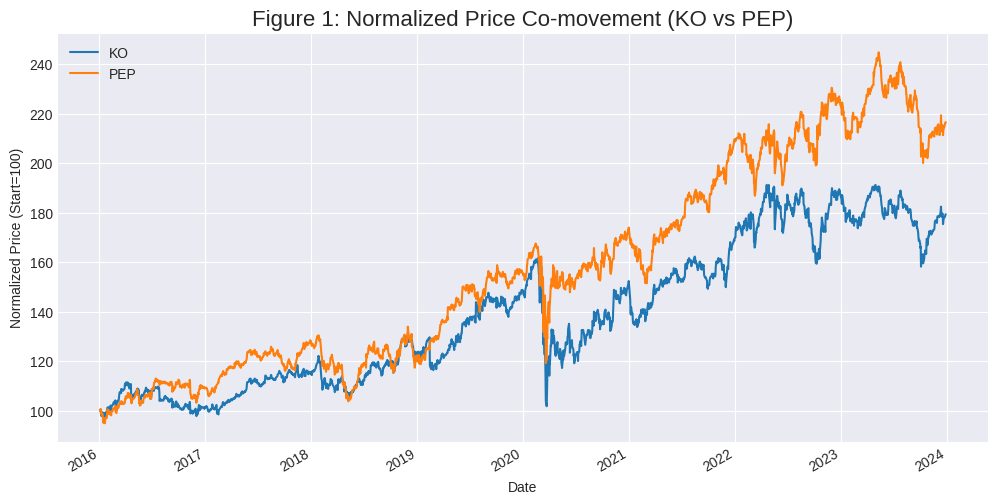

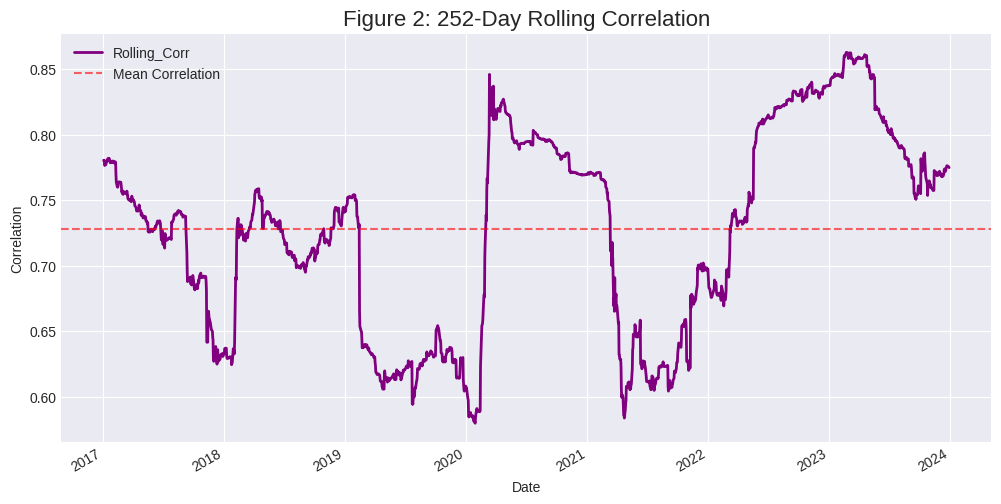

Hedge Ratio (Beta): 3.3443
P-Value: 0.018806
Statistical Justification: P-Value confirms stationarity (cointegration).

--- STRATEGY BACKTESTING ---
Backtesting over 1760 trading days

--- Performance Summary ---
          Daily Mean Return  Daily Std Dev  Annualized Return  Annualized Volatility  Sharpe Ratio  Max Drawdown (%)
Strategy           0.000195       0.005137           0.049221                0.08155      0.358317          9.813454


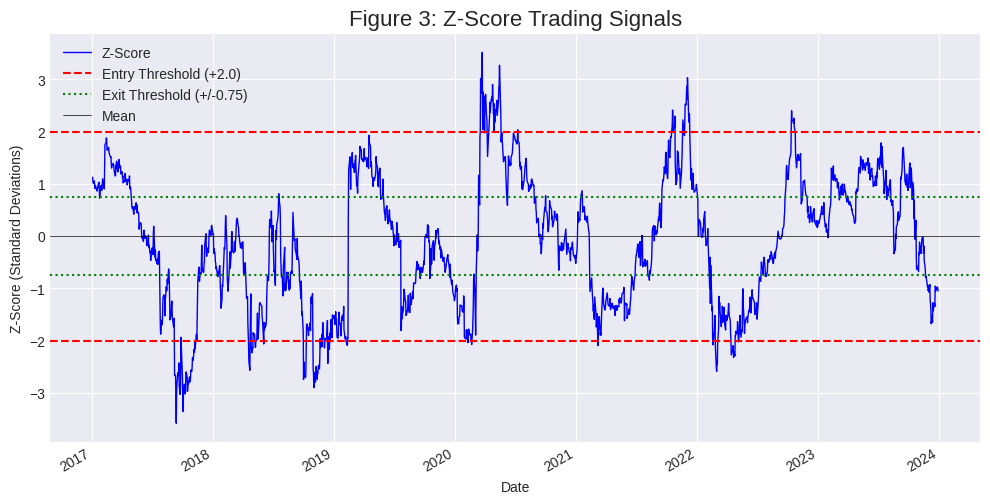

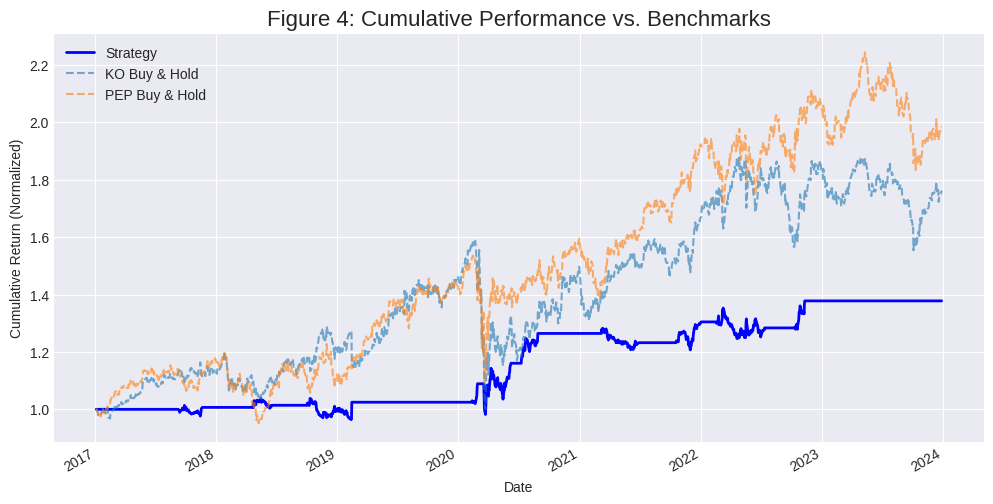


--- Final Backtest Data Sample (Trade Actions Highlighted) ---
                    X           Y     Spread   Z_Score Trade_Action  Position_X  Position_Y  Cumulative_Return
Date                                                                                                          
2023-12-15  55.233723  155.600098 -29.118392 -1.380603         FLAT           0           0           1.377786
2023-12-18  55.629601  157.379700 -28.662727 -1.280705         FLAT           0           0           1.377786
2023-12-19  55.450512  156.485229 -28.958270 -1.345729         FLAT           0           0           1.377786
2023-12-20  54.300598  154.379517 -27.218319 -0.956282         FLAT           0           0           1.377786
2023-12-21  54.658772  155.572159 -27.223518 -0.958334         FLAT           0           0           1.377786
2023-12-22  54.969810  156.233673 -27.602213 -1.047697         FLAT           0           0           1.377786
2023-12-26  55.196030  157.333130 -27.259303 -0.

In [ ]:
# Main method to call other methods

if __name__ == '__main__':
    # 1. Fetch Data
    trading_data = fetch_and_clean_data(TICKER_X, TICKER_Y, START_DATE, END_DATE)

    if not trading_data.empty:
        # 2. EDA and Modeling (Calculates Beta, Spread, Z-Score)
        trading_data, hedge_ratio = run_eda_and_modeling(trading_data, WINDOW)

        # 3. Backtest and Evaluate (Simulates the event loop)
        run_backtest_and_evaluate(trading_data, ENTRY_Z, EXIT_Z, hedge_ratio)